In [2]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
from qitp.engine.unitary_approximation import UnitaryApproximation
from qitp.engine.propagation import QITEPropagation
from qitp.engine.cqite_run import run_qite
from qitp.engine.prepare_state import constraint_rotation, prepare_state
from qitp.simulation.backend import SimulatorBackend

In [4]:
from qitp.ansatz.pauli_basis import (
    PauliBasis
)
from qitp.ansatz.commutator_basis import (
    CommutatorBasis
)

In [5]:
h1 = 1; h2 = 1; Jz = 1;

H = SparsePauliOp(
    ["XI", "IX", "ZZ"],
    coeffs=[h1, h2, Jz]
)

In [30]:
Mz = SparsePauliOp(
    ["YY"],
    coeffs=[1.0]
)

Identity = SparsePauliOp(["II"],coeffs=[1.0])

In [32]:
seeds = [
    SparsePauliOp("ZI"),
    SparsePauliOp("IZ"),
    SparsePauliOp("XI"),
    SparsePauliOp("IX")
]

In [34]:
basis = CommutatorBasis.from_seed(hamiltonian=H, seeds=seeds, depth=1)

In [36]:
basis.size

8

In [38]:
approx = UnitaryApproximation(basis)

backend = SimulatorBackend()

prop = QITEPropagation(
    H,
    approx,
    backend
)

prop.constraints = [
    Identity,
    Mz
]

In [62]:
dt=1e-1
nsteps=30
target=0.99

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [64]:
rot = constraint_rotation(
    Mz,
    target=target
)

print(
    rot["generator"]
    .paulis[0]
    .to_label()
)

print(
    rot["a"],
    rot["b"]
)

print(
    rot["theta"]
)

XY
0.0 -1.0
-0.7146284267352346


In [66]:
circuit = prepare_state(
    2,
    [rot]
)

In [68]:
circuit = circuit.decompose()

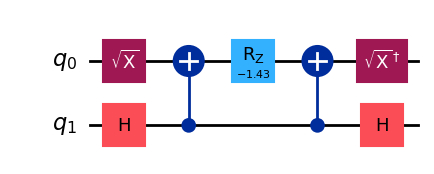

In [70]:
circuit.draw("mpl")

In [72]:
results = run_qite(
    prop,
    circuit,
    H,
    Mz,
    dt,
    nsteps
)

energies = results["energies"]
magnetizations = results["magnetizations"]

In [74]:
print(np.round(energies[-1],3))

-1.271


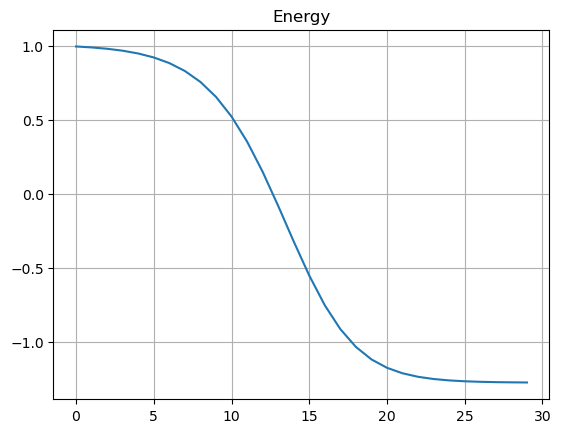

In [76]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

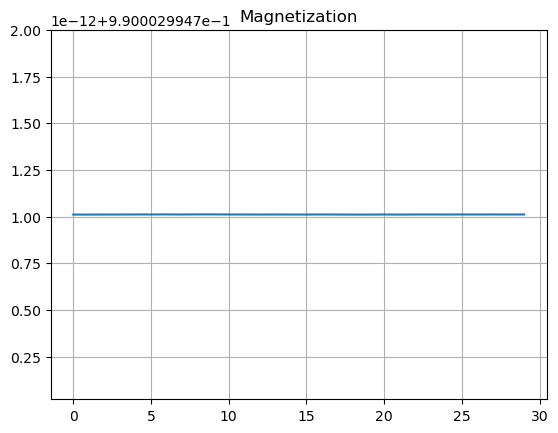

In [78]:
plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [80]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-2.24 -1.    1.    2.24]


In [82]:
import numpy as np
from scipy.optimize import root_scalar

Hm = H.to_matrix()
Mm = Mz.to_matrix()

def mz_expectation(lam):

    Hc = Hm + lam * Mm

    E, V = np.linalg.eigh(Hc)

    psi = V[:, 0]

    return np.real(
        np.vdot(
            psi,
            Mm @ psi
        )
    )


sol = root_scalar(
    lambda lam:
        mz_expectation(lam) - target,
    bracket=[-100, 100]
)

lam = sol.root

Hc = Hm + lam * Mm

E, V = np.linalg.eigh(Hc)

psi_exact = V[:, 0]

E_exact = np.real(
    np.vdot(
        psi_exact,
        Hm @ psi_exact
    )
)

print("E_exact =", np.round(E_exact,2))

E_exact = -1.27
